## 🌍 Scraping Geospatial Data

### Fetching OpenStreetMap data using overpass

#### Find all the resturatnts within a certain given distance from KFUPM

In [1]:
import requests

# KFUPM
latitude = 26.307
longitude = 50.1459
distance = 3000  # metres

overpass_query = f"""
[out:json][timeout:120];
(
  node["amenity"="restaurant"](around:{distance},{latitude},{longitude});
  way["amenity"="restaurant"](around:{distance},{latitude},{longitude});
  relation["amenity"="restaurant"](around:{distance},{latitude},{longitude});
);
out center tags;
"""

response = requests.post(
    "https://overpass-api.de/api/interpreter",
    data={"data": overpass_query},
    headers={
        # Replace this with an appropriate application name/contact.
        "User-Agent": "KFUPM-restaurant-search/1.0"
    },
    timeout=60,
)
response.raise_for_status()

elements = response.json()["elements"]

restaurants = [
    {
        "name": (
            element.get("tags", {}).get("name:en")
            or element.get("tags", {}).get("name")
            or element.get("tags", {}).get("brand")
            or "Unnamed restaurant"
        ),
        "name_ar": element.get("tags", {}).get("name:ar"),
        "osm_type": element["type"],
        "osm_id": element["id"],
    }
    for element in elements
]

for restaurant in restaurants:
    print(restaurant["name"])

Dining Hall
Kudu
Rolling Hills Golf Course Clubhouse
Tandori House Restaurant
Indian Restaurant
Kudu
Petit France
Vapiano
Pappa Roti
AJ's Pancakes
Applebee's
Unnamed restaurant
Ocean Basket
Shakespeare and Co.
Al jabal restaurant
مكبوس اكسبرس
Mr. Chicken
شعبيات الفخامة
شاورما الوادي
الخليج المتجدد
مشويات فلامينجو
منؤشة الريف
Loqmt zad
Student Restaurant
Subway
Eat'sy Restaurant
DaMichele


### Print the list of found resturants

In [2]:
# If you previously used: data = response.json()
restaurants = response.json()

print("List of Restaurants:")

restaurant_locations = []

for element in restaurants.get("elements", []):
    tags = element.get("tags", {})

    name = (
        tags.get("name:en")
        or tags.get("name")
        or tags.get("brand")
        or "Unnamed"
    )

    # Nodes store coordinates directly.
    if element["type"] == "node":
        lat = element.get("lat")
        lon = element.get("lon")

    # Ways and relations use the center returned by `out center tags`.
    else:
        center = element.get("center", {})
        lat = center.get("lat")
        lon = center.get("lon")

    if lat is not None and lon is not None:
        restaurant_locations.append((name, lat, lon))
        print(f"- {name}: Latitude: {lat}, Longitude: {lon}")

print(f"\nTotal restaurants found: {len(restaurant_locations)}")

List of Restaurants:
- Dining Hall: Latitude: 26.3081965, Longitude: 50.1287717
- Kudu: Latitude: 26.3179561, Longitude: 50.1428632
- Rolling Hills Golf Course Clubhouse: Latitude: 26.3022638, Longitude: 50.121013
- Tandori House Restaurant: Latitude: 26.3039085, Longitude: 50.1298857
- Indian Restaurant: Latitude: 26.3043419, Longitude: 50.1748335
- Kudu: Latitude: 26.3233011, Longitude: 50.1647255
- Petit France: Latitude: 26.309157, Longitude: 50.175393
- Vapiano: Latitude: 26.3079537, Longitude: 50.1696739
- Pappa Roti: Latitude: 26.3074821, Longitude: 50.1688589
- AJ's Pancakes: Latitude: 26.3101358, Longitude: 50.1691657
- Applebee's: Latitude: 26.3103879, Longitude: 50.1687318
- Unnamed: Latitude: 26.3103487, Longitude: 50.1691122
- Ocean Basket: Latitude: 26.3103726, Longitude: 50.1689973
- Shakespeare and Co.: Latitude: 26.3099036, Longitude: 50.1691405
- Al jabal restaurant: Latitude: 26.3065079, Longitude: 50.1446343
- مكبوس اكسبرس: Latitude: 26.3142717, Longitude: 50.148100

### Visualize the locations on a map

In [3]:
# Create a folium map centered at KFUPM
#!pip install folium
import folium
from IPython.display import display

# Define KFUPM location
location = (26.307, 50.1459)

# Create the map
m = folium.Map(
    location=location,
    zoom_start=13
)

# Add restaurant markers
for name, lat, lon in restaurant_locations:
    folium.Marker(
        location=[lat, lon],
        popup=name,
        tooltip=name,
        icon=folium.Icon(
            color="red",
            icon="cutlery",
            prefix="fa"
        ),
    ).add_to(m)

display(m)

### Getting data using OverPass QL

📝 **Note:**  You can compile your own dataset using the Overpass QL language that runs on [Overpass turbo](https://overpass-turbo.eu/). You can use this query language to mine OpenStreetMaps data, filter it, and get it ready to be used by osmnx or any library that parses .osm files. Below is a quick review about using Overpass API, which is the official API for reading data from OpenStreetMap servers. All the online routing services and software use it. Additionally, we will usually use Nominatim to do geocoding/geo-decoding; translating addresses to/from (latitude-longitude).

⚠️ **Warning:** Also be aware of the fact that most of the time if you are building a dataset over a very big area in the map, the graph parsed from the data by osmnx won’t be complete, even though there are physically feasible routes that could make the graph complete and connect all the nodes. This deficiency is usually because of the incomplete relations and data of osm.

### Getting data using Overpass turbo’s Wizard

Fire up [Overpass turbo](https://overpass-turbo.eu/) and run these scripts and export it as .osm files.

### Getting data using Overpass turbo’s Wizard

<a href="https://overpass-turbo.eu/">Overpass turbo</a>’s Wizard provides an easy way to auto-generate Overpass QL queries. Wizard syntax is similar to that of a search engine. An example of Wizard syntax is amenity=hospital that generates an Overpass QL query to find all the hospitals in a certain region of interest. Hospital locations will be visualized on the map and can be downloaded/copied using the “Export” button. The data can be exported as GeoJSON, GPX, KML, raw OSM data, or raw data directly from Overpass API. You can then use osmnx to read .osm files with osmnx.graph_from_xml.

***

## Fetching OpenStreetMap data using osmnx

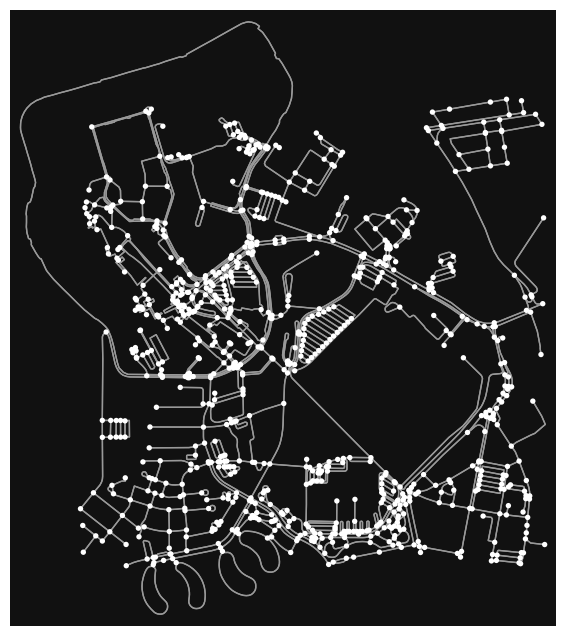

In [4]:
# !pip install osmnx

import osmnx as ox
import matplotlib.pyplot as plt


place_name = "KFUPM, Dahran, Saudi Arabia"
distance = 1000  # in meters

# fetch OSM street network (drive, walk, private, etc.) from the location
graph = ox.graph_from_address(place_name, dist=distance, network_type='walk')
fig, ax = ox.plot_graph(graph)

#### Edges and Node

We can extract the nodes and edges of the graph as separate structures.

In [5]:
nodes, edges = ox.graph_to_gdfs(graph)
nodes.head(5)

,y,x,street_count,highway,geometry
osmid,,,,,
287309367,26.305705,50.142541,3,NaN,POINT (50.14254 26.30571)
287560264,26.307124,50.160648,3,NaN,POINT (50.16065 26.30712)
287560268,26.306787,50.161143,3,NaN,POINT (50.16114 26.30679)
287560776,26.306058,50.159078,4,NaN,POINT (50.15908 26.30606)
287561129,26.306014,50.158347,3,NaN,POINT (50.15835 26.30601)


In [6]:
edges.head(5)

osmid   highway maxspeed  \
u         v           key                                 
287309367 13149804623 0     26237320  tertiary       50   
          2380677457  0     26237372  tertiary      NaN   
287560264 6578820501  0     26256802  tertiary      NaN   
          2515997858  0     26256802  tertiary      NaN   
          8863174998  0    957874490   service      NaN   

                                            name  oneway reversed      length  \
u         v           key                                                       
287309367 13149804623 0       Academic Belt Road   False    False  369.381661   
          2380677457  0    Dr Bakr Bin Bakr Road   False    False  381.847351   
287560264 6578820501  0                      NaN   False     True    8.956613   
          2515997858  0                      NaN   False    False  110.445062   
          8863174998  0                      NaN   False    False  413.484369   

                                                                    geometry  \
u         v           key                                                      
287309367 13149804623 0    LINESTRING (50.14254 26.30571, 50.14258 26.305...   
          2380677457  0    LINESTRING (50.14254 26.30571, 50.14249 26.305...   
287560264 6578820501  0    LINESTRING (50.16065 26.30712, 50.16068 26.30705)   
          2515997858  0    LINESTRING (50.16065 26.30712, 50.16048 26.307...   
          8863174998  0    LINESTRING (50.16065 26.30712, 50.16087 26.307...   

                          service lanes junction tunnel access bridge  
u         v           key                                              
287309367 13149804623 0       NaN   NaN      NaN    NaN    NaN    NaN  
          2380677457  0       NaN   NaN      NaN    NaN    NaN    NaN  
287560264 6578820501  0       NaN   NaN      NaN    NaN    NaN    NaN  
          2515997858  0       NaN   NaN      NaN    NaN    NaN    NaN  
          8863174998  0       NaN   NaN      NaN    NaN    NaN    NaN

We can further drill down to examine each individual node or edge.

In [7]:
# Rendering the 2nd node
list(graph.nodes(data=True))[1]

(287560264, {'y': 26.3071236, 'x': 50.160648, 'street_count': 3})

In [8]:
# Rendering the 1st edge
list(graph.edges(data=True))[0]

(287309367,
 13149804623,
 {'osmid': 26237320,
  'highway': 'tertiary',
  'maxspeed': '50',
  'name': 'Academic Belt Road',
  'oneway': False,
  'reversed': False,
  'length': np.float64(369.3816605981374),
  'geometry': <LINESTRING (50.143 26.306, 50.143 26.306, 50.143 26.306, 50.143 26.305, 50....>})

### Street Types
Street types can also be retrieved for the graph:

In [9]:
print(edges['highway'].value_counts())

highway
service                   1168
footway                    486
residential                402
tertiary                   268
pedestrian                  60
[steps, footway]            22
unclassified                22
primary                      8
steps                        8
tertiary_link                6
[residential, service]       2
Name: count, dtype: int64


### Calculating Network Statistics

In [10]:
ox.basic_stats(graph)

{'n': 856,
 'm': 2452,
 'k_avg': 5.728971962616822,
 'edge_length_total': 169029.8678878508,
 'edge_length_avg': 68.93550892652969,
 'streets_per_node_avg': 2.9228971962616823,
 'streets_per_node_counts': {0: 0, 1: 84, 2: 0, 3: 672, 4: 99, 5: 0, 6: 1},
 'streets_per_node_proportions': {0: 0.0,
  1: 0.09813084112149532,
  2: 0.0,
  3: 0.7850467289719626,
  4: 0.11565420560747663,
  5: 0.0,
  6: 0.0011682242990654205},
 'intersection_count': 772,
 'street_length_total': 84514.93394392535,
 'street_segment_count': 1226,
 'street_length_avg': 68.93550892652965,
 'circuity_avg': 1.2041254418787601,
 'self_loop_proportion': 0.012234910277324634}

*** 

### Visualize points of interest

In [11]:
import folium

center=(26.3071, 50.1459) # KFUPM
source_point = (26.3032, 50.1594) # Dhahran Techno Valley
destination_point = (26.3142, 50.1476) # KFUPM Mall

m = folium.Map(location=center, zoom_start=15, zoom_control=False, scrollWheelZoom=False, dragging=False)
folium.Marker(location=source_point,icon=folium.Icon(color='red',icon='university', prefix='fa')).add_to(m)
folium.Marker(location=center,icon=folium.Icon(color='blue',icon='graduation-cap', prefix='fa')).add_to(m)
folium.Marker(location=destination_point,icon=folium.Icon(color='green',icon='store', prefix='fa')).add_to(m)

m

### Finding the shortest path

Let’s find the shortest path between Dhahran Techno Valley to KFUPM Mall. To calculate this shortest path, we first need to find the closest nodes on the network to our starting and ending locations.

In [12]:
import geopandas

X = [source_point[1], destination_point[1]]
Y = [source_point[0], destination_point[0]]
closest_nodes = ox.distance.nearest_nodes(graph,X,Y)

# Get the rows from the Node GeoDataFrame
closest_rows = nodes.loc[closest_nodes]

# Put the two nodes into a GeoDataFrame
od_nodes = geopandas.GeoDataFrame(closest_rows, geometry='geometry', crs=nodes.crs)
od_nodes

,y,x,street_count,highway,geometry
osmid,,,,,
12750213299,26.303120,50.159284,3,NaN,POINT (50.15928 26.30312)
9320389165,26.313631,50.147812,4,NaN,POINT (50.14781 26.31363)


Let’s find and plot the shortest route now!

In [13]:
import networkx

shortest_route = networkx.shortest_path(G=graph,source=closest_nodes[0],target=closest_nodes[1], weight='length')
print(shortest_route)

[np.int64(12750213299), 2380687103, 6346294718, 2380687134, 2380687150, 12750213268, 287561225, 287561129, 287561134, 2380680848, 433561654, 2380680850, 433561650, 6346325383, 9570489655, 9570489662, 3326656038, 13149804647, 13149804627, 9726772823, 3326661497, 13149804643, 13131596027, 6587690331, 6582888369, 6582888370, 13131596023, 6582888357, 6582888355, 9320389175, 9320389174, np.int64(9320389165)]


### Visualize the shortest path

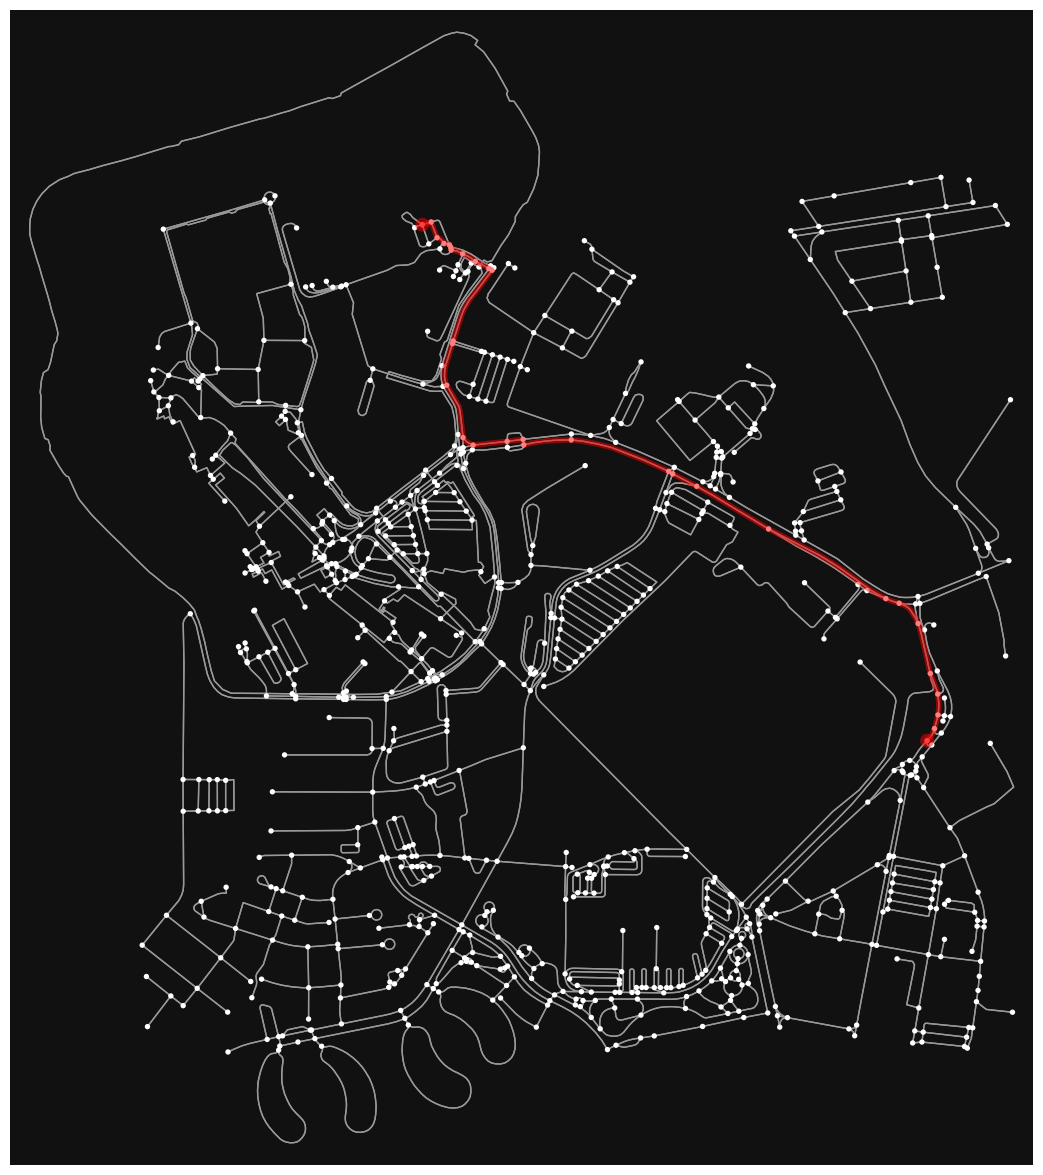

(<Figure size 1500x1500 with 1 Axes>, <Axes: >)

In [14]:
ox.plot_graph_route(graph,shortest_route,figsize=(15,15))

Let’s make a map that shows the above route, with both starting and ending nodes shown as markers using draw_route implemented as part of our Python package optalgotools.

In [15]:
# !pip install optalgotools
from optalgotools import routing

routing.draw_route(graph, shortest_route)

***
## Gas Stations in Riyadh as an example

 Let's use a dataset of public locations, such as gas stations or landmarks in Saudi Arabia, which you can retrieve via OpenStreetMap's Overpass API.

In [16]:
import time

import folium
import requests

ENDPOINTS = [
    "https://overpass-api.de/api/interpreter",
    "https://overpass.kumi.systems/api/interpreter",
]
HEADERS = {"User-Agent": "riyadh-fuel-map (alaa.rashwan@kfupm.edu.sa)"}

lat, lon = 24.7136, 46.6753  # Riyadh

overpass_query = """
[out:json][timeout:120];
node["amenity"="fuel"](24.5,46.0,25.0,47.0);  // Bounding box for Riyadh area
out body;
"""


def fetch_overpass(query, retries=3):
    """POST the query, raising a readable error instead of a JSONDecodeError."""
    last_error = None
    for endpoint in ENDPOINTS:
        for attempt in range(retries):
            try:
                response = requests.post(
                    endpoint,
                    data={"data": query},
                    headers=HEADERS,
                    timeout=180,
                )
            except requests.RequestException as exc:
                last_error = f"{endpoint}: {exc}"
                time.sleep(5 * (attempt + 1))
                continue

            if response.status_code in (429, 504):  # busy / timed out
                last_error = f"{endpoint}: HTTP {response.status_code}"
                time.sleep(10 * (attempt + 1))
                continue

            if response.status_code != 200:
                raise RuntimeError(
                    f"{endpoint} returned HTTP {response.status_code}:\n"
                    f"{response.text[:500]}"
                )

            try:
                return response.json()
            except ValueError:
                raise RuntimeError(
                    f"{endpoint} returned non-JSON (likely a query error):\n"
                    f"{response.text[:500]}"
                ) from None

    raise RuntimeError(f"All Overpass endpoints failed. Last error: {last_error}")


data = fetch_overpass(overpass_query)

# Extract the gas station data from the JSON response
stations = []
for element in data["elements"]:
    if "lat" in element and "lon" in element:
        tags = element.get("tags", {})
        address_parts = [
            tags.get("addr:housenumber"),
            tags.get("addr:street"),
            tags.get("addr:district"),
            tags.get("addr:city"),
        ]
        address = ", ".join(p for p in address_parts if p) or "N/A"
        stations.append(
            {
                "station_id": element.get("id"),
                "name": tags.get("name", "Unknown"),
                "lat": element["lat"],
                "lon": element["lon"],
                "brand": tags.get("brand", tags.get("operator", "N/A")),
                "address": address,
            }
        )

print(f"Found {len(stations)} fuel stations")

# Create a folium map centered around Riyadh
saudi_map = folium.Map(location=[lat, lon], zoom_start=12)

for station in stations:
    folium.Marker(
        location=[station["lat"], station["lon"]],
        popup=folium.Popup(
            f"Id: {station['station_id']}<br>"
            f"Name: {station['name']}<br>"
            f"Brand: {station['brand']}<br>"
            f"Address: {station['address']}",
            max_width=300,
        ),
        icon=folium.Icon(color="red", icon="info-sign"),
    ).add_to(saudi_map)

saudi_map

Found 440 fuel stations


📚 **For more information:** Please refer to this short article: [Handling Geospatial Data and Mapping in Python](https://medium.com/ai4sm/handling-geospatial-data-and-mapping-in-python-5e63326a13d5)